## Task 1: Data Understanding 

For my machine learning project, I will be using a dataset containing records of maternal deaths in Kenya across its 47 counties. Access to safe, quality, and reliable maternal healthcare in Kenya is a major challenge. My objective is to train a binary classification model that can accurately predict the likelihood of an individual maternal mortality event (maternal_death). 

By identifying key risk factors, this model aims to provide actionable insights so that respective county governments can proactively allocate the necessary resources to ensure their residents receive adequate care.

The dataset, comprising 6,000 instances and 22 features, contains various indicator levels which I will explore:
- Level 1 (Individual Women) - these are the columns which contain the respondent's information such as age, parity (total number of live births a woman has had up to the index pregnancy), education level, anc_visits (number of antenatal care visits attended during the index pregnancy), place_delivery (the location where the baby was delivered) etc.. 
- Level 2 (Household Indicators) - these are the columns which contain information such as wealth_quantile the individual belongs to, their household size, the distance from their nearest facility and their rate of seeking health care.
- Level 3 (County-Level Predictors) - these are the columns which contain county information such as name of the county, urbanization status, poverty rate, number of health facilities, sba_coverage (% of births attended by skilled birth attendants), county_edu_index (the composite county education index based on literacy rate, years of schooling and female secondary completion) and the HIV prevalence rate amongst adults.

The dataset was obtained from the Kenya Demographic and Health Survey (KDHS) 2022 via Kaggle (https://www.kaggle.com/datasets/lumumbavictor/maternal-mortality-rate)

The first step is to import the relevant libraries for this project.

In [316]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics
sns.set()

Now I will load the dataset.

In [317]:
df = pd.read_csv('kdhs_2022_data_maternal_mortality.csv')
df.head(10)

,county,age,parity,education,anc_visits,place_delivery,skilled_attendant,c_section,postnatal48h,marital_status,...,wealth_quintile,household_size,distance_facility,urbanization,health_facility_density,poverty_rate,sba_coverage,county_edu_index,hiv_prev,maternal_death
0,Bungoma,27,5,Secondary,3,Public,Skilled,0,1,Married,...,4,7,46,Rural,14.1,39.5,54.8,56.2,8.1,No
1,Isiolo,27,1,Higher,2,Public,Skilled,0,1,Married,...,3,4,38,Rural,10.0,36.2,62.0,66.5,2.6,No
2,Kitui,25,2,Secondary,6,Private,Skilled,0,1,Not in union,...,2,2,48,Rural,15.0,12.9,91.3,91.1,4.4,No
3,Kajiado,24,1,Primary,6,Public,Skilled,0,0,Married,...,1,6,37,Rural,13.4,58.2,75.9,79.3,8.4,No
4,Tana River,33,2,Primary,2,Private,Skilled,1,1,Not in union,...,5,6,30,Rural,3.2,45.2,99.3,93.8,5.3,No
5,Lamu,28,2,Primary,5,Public,Skilled,0,0,Married,...,3,2,25,Urban,10.0,39.3,81.4,87.6,8.1,No
6,Kisii,20,1,Higher,6,Public,Skilled,1,0,Not in union,...,4,1,6,Rural,13.1,18.6,60.4,72.3,3.7,No
7,Kitui,29,1,Primary,3,Public,Skilled,0,1,Married,...,4,3,39,Urban,12.1,55.4,53.7,69.2,4.6,Yes
8,Nakuru,22,1,Higher,5,Home,Not Skilled,0,0,Married,...,2,5,38,Rural,11.7,51.1,79.1,54.6,9.4,No
9,Narok,15,1,Secondary,4,Home,Not Skilled,0,1,Married,...,3,10,40,Urban,13.5,19.0,81.2,75.3,7.6,No


The dataset has loaded correctly. Now I will proceed to explore the data to see what I am working with.

In [318]:
df.info()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   county                   6000 non-null   object 
 1   age                      6000 non-null   int64  
 2   parity                   6000 non-null   int64  
 3   education                5404 non-null   object 
 4   anc_visits               6000 non-null   int64  
 5   place_delivery           6000 non-null   object 
 6   skilled_attendant        6000 non-null   object 
 7   c_section                6000 non-null   int64  
 8   postnatal48h             6000 non-null   int64  
 9   marital_status           6000 non-null   object 
 10  age_first_birth          6000 non-null   int64  
 11  birth_interval           6000 non-null   int64  
 12  wealth_quintile          6000 non-null   int64  
 13  household_size           6000 non-null   int64  
 14  distance_facility       

np.int64(0)

From the information above, I can see that I am missing 596 records in the Education column. Additionally, the wealth_quintile column has been categorized as an int64 object but it should be treated as an ordinal category representing the household socioeconomic status categories i.e. poorest, poorer, middle, richer and richest. 

I also verified that there are zero duplicate records in the dataset.

In [319]:
df.describe()

,age,parity,anc_visits,c_section,postnatal48h,age_first_birth,birth_interval,wealth_quintile,household_size,distance_facility,health_facility_density,poverty_rate,sba_coverage,county_edu_index,hiv_prev
count,6000.00000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,27.08850,2.102167,3.507167,0.126000,0.693333,22.052667,39.093333,2.765333,5.005833,27.560667,8.500367,35.147717,75.238850,72.438367,6.019683
std,5.88751,1.263986,1.708148,0.331877,0.461148,6.312992,12.065911,1.265253,2.266787,13.101473,3.762263,14.319559,14.429723,13.084214,2.309545
min,15.00000,1.000000,1.000000,0.000000,0.000000,3.000000,18.000000,1.000000,0.000000,5.000000,2.000000,10.000000,50.000000,50.000000,2.000000
25%,23.00000,1.000000,2.000000,0.000000,0.000000,18.000000,29.000000,2.000000,3.000000,16.000000,5.300000,22.800000,62.875000,61.100000,4.100000
50%,27.00000,2.000000,3.000000,0.000000,1.000000,22.000000,39.000000,3.000000,5.000000,28.000000,8.600000,35.150000,75.450000,72.700000,6.000000
75%,31.00000,3.000000,5.000000,0.000000,1.000000,26.000000,49.000000,4.000000,6.000000,39.000000,11.700000,47.500000,87.825000,83.500000,8.000000
max,47.00000,9.000000,6.000000,1.000000,1.000000,43.000000,60.000000,5.000000,16.000000,50.000000,15.000000,60.000000,100.000000,95.000000,10.000000


From the information above, I can already note an error under the age_first_birth column. This column contains information about how old a patient was when she had her first baby. Under the min category, I have a value of 3 which is unrealistic because that would mean that the respondent was 3 years old when she had her first baby. Under the household_size column, we have a min value of 0 which is also unrealistic because that would mean that there is no one in that household.

I will proceed to explore the categorical "object" columns to finish auditing the dataset before moving on to clean these anomalies in the data preparation phase of my project.

In [320]:
df.describe(include='object')

,county,education,place_delivery,skilled_attendant,marital_status,urbanization,maternal_death
count,6000,5404,6000,6000,6000,6000,6000
unique,47,3,3,2,2,2,2
top,Laikipia,Primary,Public,Skilled,Married,Rural,No
freq,159,2374,2980,4141,4175,4193,5394


From the output above, I can see that all of Kenya's 47 counties are represented within the dataset, with Laikipia being the most frequently represented county with 159 instances. However, I am concerned with the frequency of "No" under the maternal_death column. This severe class imbalance could easily skew my model to simply predict the Class 0 (No maternal deaths) cases, so I will need to handle this carefully during the evaluation phase by prioritizing metrics like the F1-score or recall over standard accuracy.

Another interesting thing to note is that the majority of the respondents captured within the dataset are from rural areas. While this demographic split is useful because it allows me to explore how maternal_death compares between urban and rural settings, I must acknowledge that it will not give us the full picture. Since the dataset is so heavily imbalanced toward rural respondents, any direct comparisons will need to be interpreted with caution.

Before proceeding to do my visualizations, I will first check if all Kenyan county names have been entered correctly. I want to double-check this because I encountered an issue in Assignment 2 of the Interactive Dashboards module where the Kenyan county names were misspelled in the dataset I was working with.

In [321]:
print(sorted(df['county'].unique()))

['Baringo', 'Bomet', 'Bungoma', 'Busia', 'Elgeyo-Marakwet', 'Embu', 'Garissa', 'Homa Bay', 'Isiolo', 'Kajiado', 'Kakamega', 'Kericho', 'Kiambu', 'Kilifi', 'Kirinyaga', 'Kisii', 'Kisumu', 'Kitui', 'Kwale', 'Laikipia', 'Lamu', 'Machakos', 'Makueni', 'Mandera', 'Marsabit', 'Meru', 'Migori', 'Mombasa', "Murang'a", 'Nairobi', 'Nakuru', 'Nandi', 'Narok', 'Nyamira', 'Nyandarua', 'Nyeri', 'Samburu', 'Siaya', 'Taita Taveta', 'Tana River', 'Tharaka-Nithi', 'Trans Nzoia', 'Turkana', 'Uasin Gishu', 'Vihiga', 'Wajir', 'West Pokot']


Now that I have confirmed that all Kenyan counties have been named correctly, I will proceed to visualize some of the numerical features within the dataset such as age_first_birth, anc_visits, distance_facility, and poverty_rate to better understand their distributions.

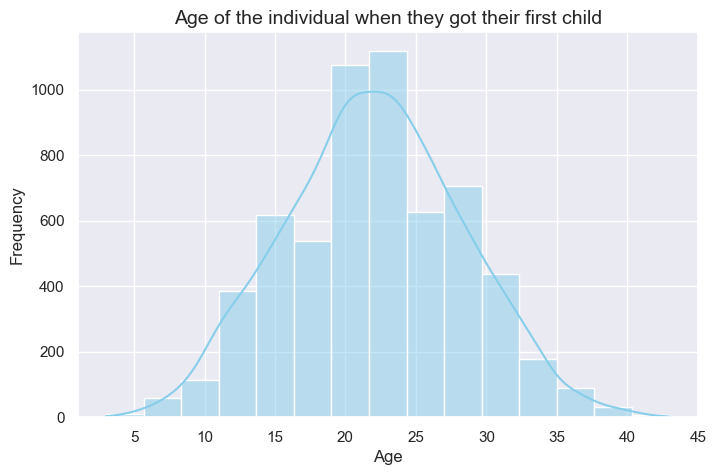

In [322]:
plt.figure(figsize=(8, 5))
sns.histplot(df['age_first_birth'], bins=15, kde=True, color='skyblue')
plt.title('Age of the individual when they got their first child', fontsize=14)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

Based on the visualization above, I can see that the majority of the respondents had their first child between the ages of 18 and 24, and this frequency steadily decreases as age increases. However, there are a few severe outlier values which I will definitely need to address in Task 2, such as records indicating respondents had their first child at the age of 3.

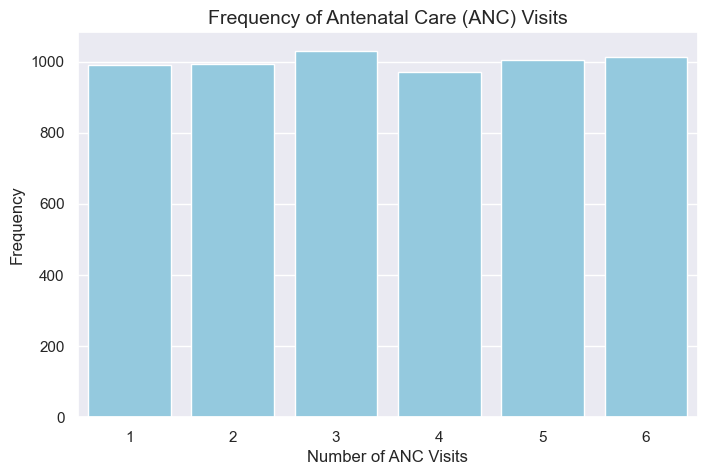

In [323]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='anc_visits', color='skyblue')
plt.title('Frequency of Antenatal Care (ANC) Visits', fontsize=14)
plt.xlabel('Number of ANC Visits')
plt.ylabel('Frequency')
plt.show()

I was interested in seeing how Kenya compares to the World Health Organization's (WHO) current recommendation of a minimum of 8 antenatal (anc) clinic visits for an expectant mother. Antenatal clinics are clinics that provide vital, routine care during pregnancy, including health screenings e.g. blood pressure, ultrasound scans, HIV tests, Hepatitis tests, immunizations and prenatal vitamins. 

WHO set this figure to 8 so that they could reduce perinatal mortality and improve women's experience of care. (https://lstmed.ac.uk/news/eight-and-more-antenatal-care-contacts-in-pregnancy-is-it-feasible/)

From the visualisation above, I can see that all the respondents in this dataset did not meet the threshold. Majority of the respondents made 3 visits to the antenatal clinics. This could be due to multiple factors such as distance to the nearest health facility, poverty rate etc...

My next visualization will focus on the distance_facility column. The distance to the nearest health facility represents one critical factor in the 'Three Delays' model framework: the delay in reaching a healthcare facility. The other two factors are the delay in deciding to seek care, and the delay in receiving adequate and appropriate care at the facility (which I will explore using the skilled_attendant column to evaluate how the presence of skilled birth attendants relates to maternal deaths).

To contextualize this data, I will reference the Kenya Health Sector Strategic Investment Plan, which recommends that health service providers be physically located near population residences at a maximum distance of 5 km (or 1 hour of travel time). This standard aligns with the recommended international thresholds established by the World Health Organization. 
(https://www.frontiersin.org/journals/public-health/articles/10.3389/fpubh.2022.1002975/full#s4)

C:\Users\apsmu\AppData\Local\Temp\ipykernel_4252\14310624.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='distance_category', order=labels, palette='viridis')


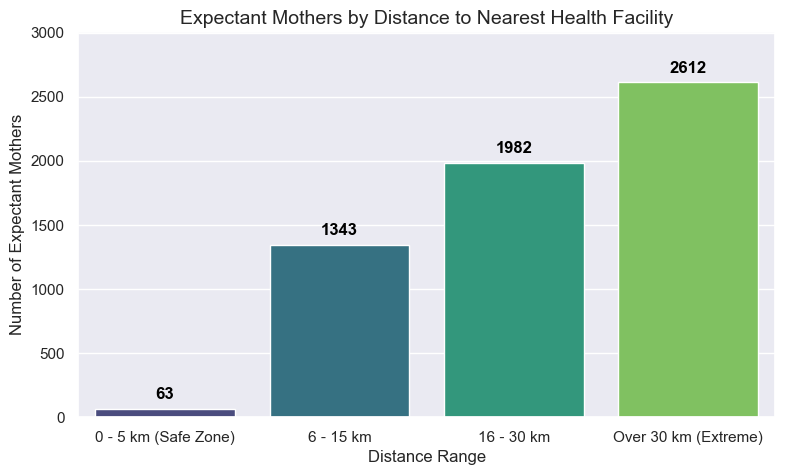

In [324]:
# Define my custom distance bins and their corresponding labels
# The bins represent edges: 0 to 5, 5 to 15, 15 to 30, and 30 to infinity
bins = [0, 5, 15, 30, np.inf]
labels = ['0 - 5 km (Safe Zone)', '6 - 15 km', '16 - 30 km', 'Over 30 km (Extreme)']

# Create the temporary categorical column using pd.cut
df['distance_category'] = pd.cut(df['distance_facility'], bins=bins, labels=labels, right=True)

plt.figure(figsize=(9, 5))

# Create the countplot using the new categories
ax = sns.countplot(data=df, x='distance_category', order=labels, palette='viridis')

# Add the exact count numbers on top of each bar
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', 
                    fontsize=12, fontweight='bold', color='black', xytext=(0, 5), 
                    textcoords='offset points')

plt.title('Expectant Mothers by Distance to Nearest Health Facility', fontsize=14)
plt.xlabel('Distance Range')
plt.ylabel('Number of Expectant Mothers')

plt.ylim(0, df['distance_category'].value_counts().max() * 1.15) 
plt.show()

From the output above, I can observe that out of the entire dataset, only 63 women were located within the recommended 5 km safe zone, while a majority of 2,612 respondents were located over 30 km away. To take this exploratory data analysis further, I want to investigate the relationship between these extreme distances and the target variable (maternal_death) by visualizing how many maternal deaths occurred among the respondents geographically isolated from their nearest health facility.

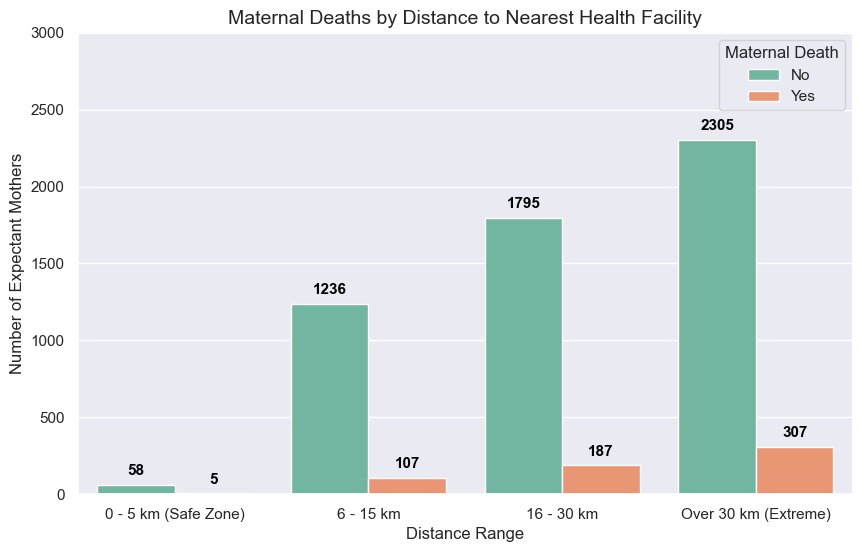

In [325]:
bins = [0, 5, 15, 30, np.inf]
labels = ['0 - 5 km (Safe Zone)', '6 - 15 km', '16 - 30 km', 'Over 30 km (Extreme)']

plt.figure(figsize=(10, 6))

# Create the countplot, now split by maternal_death
ax = sns.countplot(data=df, x='distance_category', hue='maternal_death', order=labels, palette='Set2')

# Add the exact count numbers on top of each bar
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', 
                    fontsize=11, fontweight='bold', color='black', xytext=(0, 5), 
                    textcoords='offset points')

plt.title('Maternal Deaths by Distance to Nearest Health Facility', fontsize=14)
plt.xlabel('Distance Range')
plt.ylabel('Number of Expectant Mothers')
plt.legend(title='Maternal Death')

# Dynamically scale the y-axis to fit the text labels
plt.ylim(0, df['distance_category'].value_counts().max() * 1.15) 
plt.show()

# Drop the temporary column
df.drop('distance_category', axis=1, inplace=True)

As I had earlier suspected, as the distance to the nearest health facility increased, so did the number of maternal deaths. This clearly illustrates the severe consequences of the 'Second Delay', the delay in reaching a healthcare facility, which I mentioned earlier.

Now that I have visualized some of the numerical features within my dataset, I will proceed to visualize some of the categorical features,

C:\Users\apsmu\AppData\Local\Temp\ipykernel_4252\2964857239.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='maternal_death', y='poverty_rate', data=df, palette='rainbow')


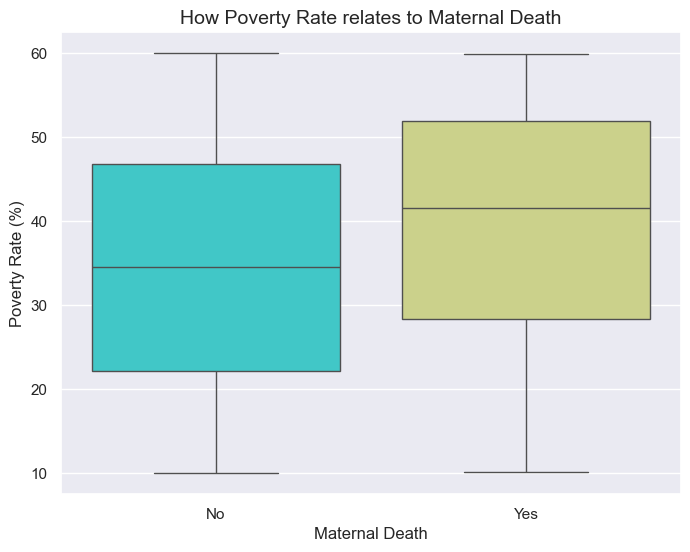

In [326]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='maternal_death', y='poverty_rate', data=df, palette='rainbow')
plt.title('How Poverty Rate relates to Maternal Death', fontsize=14)
plt.xlabel('Maternal Death')
plt.ylabel('Poverty Rate (%)')
plt.show()

From the boxplot above, I can see a clear relationship between the poverty rate and maternal death. For instances where there was no maternal death, the median poverty rate is about 34%. However, for the "Yes" instances, the median rises to roughly 41%. This illustrates that maternal deaths are more concentrated in counties with higher poverty rates.

I now want to explore the "thrid delay" - delay in receiving adequate and appropriate care which I had mentioned earlier using the skilled_attendant column. I will use this column to see the relation between a skilled attendant being present during childbirth and a maternal death occuring.

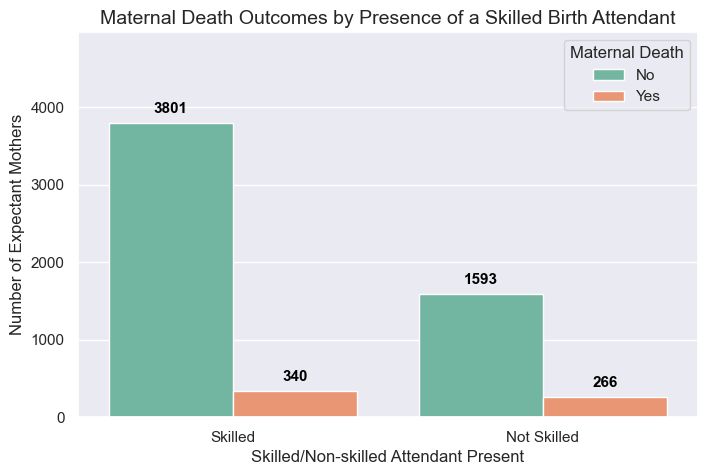

In [327]:
plt.figure(figsize=(8, 5))

# Grouped bar chart for skilled_attendant, split by maternal_death
ax = sns.countplot(data=df, x='skilled_attendant', hue='maternal_death', palette='Set2')

# Add the exact count numbers on top of each bar
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='bottom', 
                    fontsize=11, fontweight='bold', color='black', xytext=(0, 5), 
                    textcoords='offset points')

plt.title('Maternal Death Outcomes by Presence of a Skilled Birth Attendant', fontsize=14)
plt.xlabel('Skilled/Non-skilled Attendant Present')
plt.ylabel('Number of Expectant Mothers')
plt.legend(title='Maternal Death')

# Scale the y-axis to ensure the text labels fit nicely
plt.ylim(0, df['skilled_attendant'].value_counts().max() * 1.2) 
plt.show()

The output above initially tells a very different story to what I anticipated. Out of the 606 maternal deaths displayed in the visualization, the majority of them (340) occurred when a skilled birth attendant was present, while the rest (266) occurred when there was no skilled birth attendant present.

In this dataset, however, it is important to note that the majority of the respondents (4141) had a skilled birth attendant present. This means, the data is imbalanced, which visually skews the absolute counts in the chart. To accurately capture the relationship between maternal deaths and the absence or presence of a skilled birth attendant, I must calculate their respective mortality rates:

- Skilled Birth Attendant Present: 4,141 out of 6,000 respondents had a skilled birth attendant. The mortality rate is 340/4141, which is equivalent to 8.2%.
- No Skilled Birth Attendant: 1,859 out of 6,000 respondents did not have a skilled birth attendant present. The mortality rate is 266/1859, which is equivalent to 14.3%.

In conclusion, these mortality rates validate my initial assumption that the presence of a skilled birth attendant significantly reduces the risk of maternal death.

My final visualization will explore how a respondent's education level relates to maternal death. This feature aligns closely with the 'First Delay' - the delay in deciding to seek care. A lower education level often correlates with reduced health literacy, such as not recognizing the critical danger signs during pregnancy that necessitate immediate medical attention.

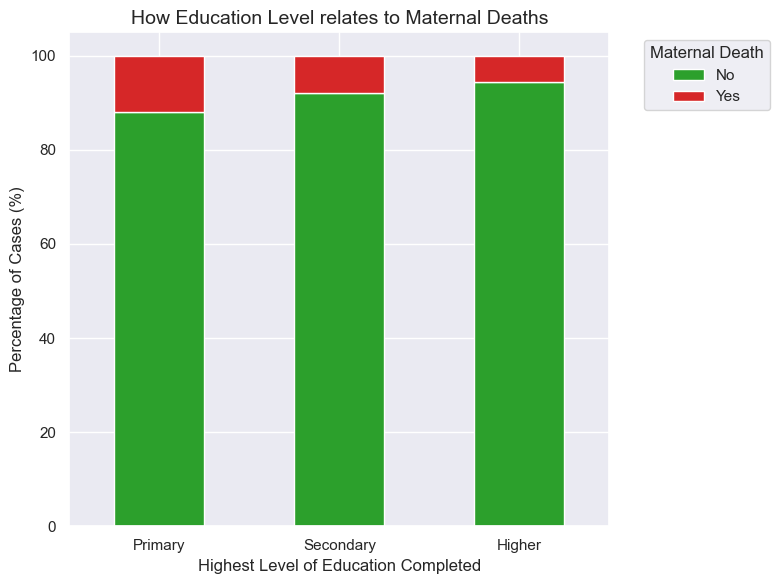

In [328]:
# Calculate the cross-tabulation and normalize it to get percentages
edu_mortality = pd.crosstab(df['education'], df['maternal_death'], normalize='index') * 100

# Reorder the index so it flows logically from lowest to highest education
edu_mortality = edu_mortality.reindex(['Primary', 'Secondary', 'Higher'])

# Create the stacked bar chart
edu_mortality.plot(kind='bar', stacked=True, figsize=(8, 6), color=['#2ca02c', '#d62728'])

plt.title('How Education Level relates to Maternal Deaths', fontsize=14)
plt.xlabel('Highest Level of Education Completed')
plt.ylabel('Percentage of Cases (%)')
plt.legend(title='Maternal Death', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

From the stacked bar chart above, I can clearly see that the percentage of maternal deaths is higher where the level of education is lower and the percentage steadily decreases as the level of education increases. This potentially points to the impact of the 'First Delay' - the delay in deciding to seek care due to the lack of proper health literacy. This can be an important factor for the national and county governments to consider. 

I am also interested in seeing how age relates to maternal deaths. To do this, I will create various bins to represent the ages within my dataset according to their risk profile, which is informed by recent literature on the divergent epidemiology of maternal mortality in Sub-Saharan Africa. 
(https://www.researchgate.net/publication408301110_Divergent_Epidemiology_of_Maternal_Mortality_in_Sub-Saharan_Africa_The_Case_for_Differentiated_Regional_Strategies_to_Achieve_2030_SDG_Targets) 

Research indicates that age-extreme populations face significantly elevated risks for maternal mortality. Therefore, Bin 1 will represent individuals from the age of 15 and 19 (High Risk Teenagers), Bin 2 will represent individuals from the age of 20 to 34 (Low Risk Adults) and Bin 3 will represent individuals from the age of 35 to 49 (High Risk Adults).

C:\Users\apsmu\AppData\Local\Temp\ipykernel_4252\727148795.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=age_risk_df, x='age_group', y='maternal_death', palette=['#d62728', '#2ca02c', '#d62728'])


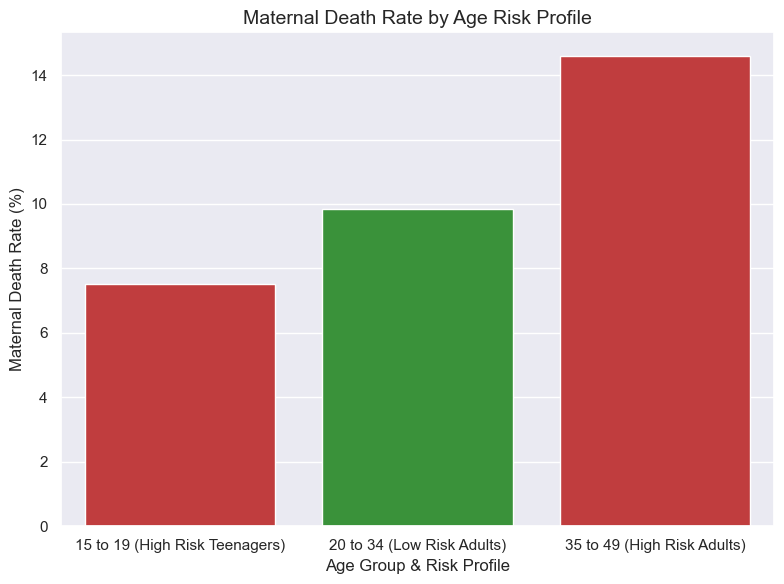

In [329]:
# Create Age Group Bins
# Using 14 as the first bin edge so that 15 is correctly included in the first bin
bins = [14, 19, 34, 49]
labels = ['15 to 19 (High Risk Teenagers)', '20 to 34 (Low Risk Adults)', '35 to 49 (High Risk Adults)']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels)

# Calculate mortality percentages for each age group
age_risk_df = df.groupby('age_group', observed=False)['maternal_death'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()

# Create the visualization
plt.figure(figsize=(8, 6))

# Using red for High Risk and green for Low Risk
sns.barplot(data=age_risk_df, x='age_group', y='maternal_death', palette=['#d62728', '#2ca02c', '#d62728'])

plt.title('Maternal Death Rate by Age Risk Profile', fontsize=14)
plt.xlabel('Age Group & Risk Profile')
plt.ylabel('Maternal Death Rate (%)')
plt.tight_layout()
plt.show()

# Drop the temporary column
df = df.drop(columns=['age_group'])

From the bar chart above, the data reveals a surprising trend that challenges the risk profiles which I used for the age group bins I created. For the 15 to 19 age group, which I noted to be high risk, the maternal death rate is actually the lowest at roughly 7.5%, while the 20 to 34 age group, which I noted to be low risk, has a higher mortality rate of around 9.8%. The risk profile assigned to the 35 to 49 age group is accurate, because the mortality rate peaks at approximately 14.5%.

Another interesting thing to note is that while being an older adult between the age of 35 and 49 is a definitive risk factor, the lower maternal death rate for teenagers shows that this specific dataset doesn't perfectly align with generalized clinical profiles probably because the average age in this dataset is 27 which means that the 15-19 age group is not sufficiently represented. 

## Task 2: Data Preparation & Modeling 

My first step will be to address the extreme outlier values in the age_first_birth column. For the purpose of this project, I will only retain records where the age at first birth is 12 years or older (age_first_birth >= 12). This decision is in line with research analyzing Demographic and Health Survey (DHS) data across Sub-Saharan Africa, which establishes 12 years as the standard demographic baseline for early adolescent childbearing.
(https://obgyn.onlinelibrary.wiley.com/doi/10.1111/j.1600-0412.2012.01467.x)

Rather than dropping the records where the age is less than 12 years and risking further dataset imbalance (I noted this when talking about the skilled_attendant column above), I will use imputation to replace these outlier values. I will calculate the median age_first_birth exclusively from the training dataset and use it to replace the outliers. To strictly prevent data leakage, this training median will then be applied consistently to handle outliers in both the validation and test datasets. 

I will also perform imputation to correct invalid and missing data in other features. Specifically, I will address instances where household_size was incorrectly recorded as 0, and impute the missing values present within the education categorical column to the most frequent education level represented in my training dataset.

To begin Task 2, I will first perform the train/test data split. I will use 70% of the dataset to train the models, and then evenly divide the remaining 30% to create a 15% validation set and a 15% test set.

## Data Splitting

In [330]:
from sklearn.model_selection import train_test_split

X = df.drop('maternal_death', axis=1)
y = df['maternal_death']

# First split: 70% Train, 30% Temp (which will become Validation and Test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=4)

# Second split: Split the 30% Temp equally into 15% Test and 15% Validation
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=4)

print('Train set:', X_train.shape,  y_train.shape)
print('Validation set:', X_valid.shape, y_valid.shape)
print('Test set:', X_test.shape,  y_test.shape)

Train set: (4200, 21) (4200,)
Validation set: (900, 21) (900,)
Test set: (900, 21) (900,)


I have successfully split my dataset. I will now proceed to impute the outlier values in the age_first_birth column.

## Preprocessing and Feature Engineering

The first step is the imputation of the age_first_birth column.

In [331]:
# Calculate the median age from the TRAINING set
median_age = X_train['age_first_birth'].median()

# Replace any age < 12 with the training median across all sets
for df_subset in [X_train, X_valid, X_test]:
    df_subset.loc[df_subset['age_first_birth'] < 12, 'age_first_birth'] = median_age

# Verify the changes
print(f"Minimum age in training set after imputation: {X_train['age_first_birth'].min()}")

Minimum age in training set after imputation: 12


The next step is to impute the records within the household_size column from 0 to 1 because it is not possible to have a household with 0 people. 

In [332]:
# Replace 0s with 1 across all sets, as a household must have at least 1 member
for df_subset in [X_train, X_valid, X_test]:
    df_subset.loc[df_subset['household_size'] == 0, 'household_size'] = 1

# Verify the changes
print(f"Minimum household size in training set after correction: {X_train['household_size'].min()}")

Minimum household size in training set after correction: 1


The final imputation step is to replace the missing values within the education column with the most frequent education level represented in the training dataset.

In [333]:
# Find the most frequent category (mode) from the TRAINING set
mode_education = X_train['education'].mode()[0]

# Fill missing values with the training mode across all sets
for df_subset in [X_train, X_valid, X_test]:
    df_subset['education'] = df_subset['education'].fillna(mode_education)

# Verify the changes
print(f"Missing values in X_train education after imputation: {X_train['education'].isnull().sum()}")

Missing values in X_train education after imputation: 0


My dataset is now clean. I will now proceed to do feature encoding/representation. 

For the target column/feature, maternal_death, I mapped the outcomes to a binary 0 and 1 format. For the education column which is logically ranked, I will use ordinal encoding. For the remaining columns/features (county, place_delivery, marital_status, urbanization, and skilled_attendant), I will use one-hot Encoding to create dummy variables. 

To strictly prevent data leakage and ensure model compatibility, I will align the columns of the validation and test sets to perfectly match the columns generated from the training set, filling any missing categories with zeros.

In [334]:
# Step 1: Binary Encoding for maternal_death (Target Variable y)
target_mapping = {'No': 0, 'Yes': 1}

y_train = y_train.map(target_mapping)
y_valid = y_valid.map(target_mapping)
y_test = y_test.map(target_mapping)

# Step 2: Ordinal Encoding for education 
# Define the logical rank for the levels of education represented in my dataset
edu_mapping = {'None': 0, 'Primary': 1, 'Secondary': 2, 'Higher': 3}

for df_subset in [X_train, X_valid, X_test]:
    df_subset['education'] = df_subset['education'].map(edu_mapping)

# Step 3: One-Hot Encoding for Nominal Columns
nominal_cols = [
    'county', 
    'place_delivery', 
    'marital_status', 
    'urbanization', 
    'skilled_attendant'
]

# Apply one-hot encoding to the nominal columns
X_train = pd.get_dummies(X_train, columns=nominal_cols, drop_first=True)
X_valid = pd.get_dummies(X_valid, columns=nominal_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=nominal_cols, drop_first=True)

# Column Alignment to prevent data leakage and ensure model compatibility
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Verification
print("Encoding Complete!")
print(f"X_train final shape: {X_train.shape}")
print(f"y_train final shape: {y_train.shape}")

Encoding Complete!
X_train final shape: (4200, 67)
y_train final shape: (4200,)


The final step will be to standardise some of the columns that contain data that might be sensitive to scale (age_first_birth & household_size) when using algorithms such as Support Vector Machine (SVM). I am doing this so that I can ensure that they are on the same scale as the newly created dummy variables for the nominal columns.

In [335]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Define the continuous numerical columns to scale
num_cols = [
    'age', 
    'age_first_birth', 
    'birth_interval', 
    'distance_facility', 
    'household_size', 
    'poverty_rate',	
    'sba_coverage',	
    'county_edu_index'
    ]
 

# Fit the scaler on the TRAINING set, then transform all sets
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_valid[num_cols] = scaler.transform(X_valid[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# Verification
print(X_train[num_cols].head())

           age  age_first_birth  birth_interval  distance_facility  \
5735  0.674475         0.770582        0.734044           0.038012   
5283  1.015159         1.300915        1.642554           0.267721   
3466  0.844817         1.124137        1.394779           0.650571   
3781  1.866871         2.008026       -0.587424          -1.340248   
4841  0.844817         0.593805        1.394779           1.416271   

      household_size  poverty_rate  sba_coverage  county_edu_index  
5735       -0.879112      1.201792     -0.071882         -1.689509  
5283       -0.431510     -1.437192      0.941756         -1.421476  
3466       -1.774316     -1.409340     -0.905009         -0.020050  
3781        0.463694     -0.497184      0.573792          0.209693  
4841        0.911296     -0.100292     -0.280164         -1.375528  


Everything looks good. I will now proceed to save the datasets into their respective .CSV files.

In [336]:
import os

# Create a directory to store the datasets
os.makedirs('preprocessed_data', exist_ok=True)

# Export the feature datasets (X) without the index column
X_train.to_csv('preprocessed_data/X_train_clean.csv', index=False)
X_valid.to_csv('preprocessed_data/X_valid_clean.csv', index=False)
X_test.to_csv('preprocessed_data/X_test_clean.csv', index=False)

# Export the target datasets (y) 
y_train.to_csv('preprocessed_data/y_train_clean.csv', index=False)
y_valid.to_csv('preprocessed_data/y_valid_clean.csv', index=False)
y_test.to_csv('preprocessed_data/y_test_clean.csv', index=False)

# Verification
print("All datasets have been successfully saved to the 'preprocessed_data' folder!")

All datasets have been successfully saved to the 'preprocessed_data' folder!


Since I am doing a classification task, I will use the following algorithms which we covered in class:
- Logistic Regression: I am using this as my baseline model because it is straightforward and gives a clear probability of an outcome (0 or 1), which makes it easy to interpret.
- Decision Trees: I selected this because it is simple to understand, interpret and use and does not heavily emphasize single features when making a prediction.
- Random Forest: I will use this as a powerful upgrade to the standard Decision Tree. Single trees are sensitive to small training variations and are prone to overfitting, but Random Forest solves this through ensemble learning.
- Support Vector Machine (SVM): I am including SVM because it is a core, standard algorithm for classification tasks. Since it is sensitive to the magnitude of variables as I had noted earlier, standardising the numerical features in the previous step ensures that it will process the data correctly.
- Naive Bayes: I will use this because it serves as a good comparative model to evaluate against the more complex distance-based and tree-based algorithms. This is because it is based on probability rather than searching for complex interactions, which provides a clean baseline to see if the more advanced models are actually adding real value or if a simpler, probabilistic approach might be sufficient.

I will start with Logistic Regression

--- Initial Logistic Regression Performance ---
Training Data Accuracy:   0.9033
Validation Data Accuracy: 0.8978

Confusion Matrix (Validation):
[[806   2]
 [ 90   2]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.90      1.00      0.95       808
           1       0.50      0.02      0.04        92

    accuracy                           0.90       900
   macro avg       0.70      0.51      0.49       900
weighted avg       0.86      0.90      0.85       900



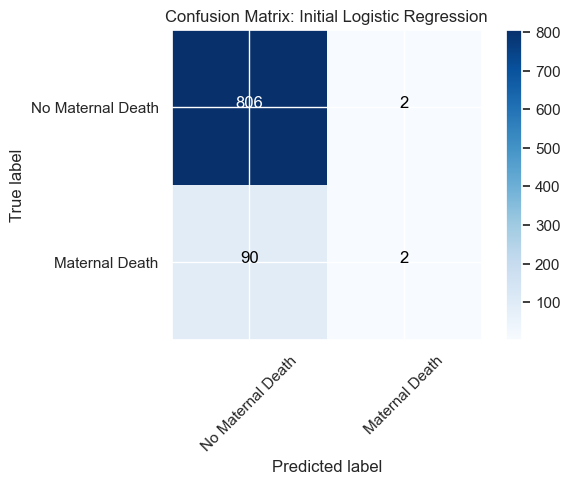

In [337]:
import matplotlib.pyplot as plt
import numpy as np
import itertools
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Define plot_confusion_matrix
def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion Matrix', cmap=plt.cm.Blues):
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)
    
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], 'd'), horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

# Initialize the Logistic Regression model
log_model = LogisticRegression(random_state=42)

# Define class names for the confusion matrix plots
class_names = ['No Maternal Death', 'Maternal Death']

# Train the model on the training data
log_model.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = log_model.predict(X_train)
valid_pred = log_model.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
log_conf_matrix = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Initial Logistic Regression Performance ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(log_conf_matrix)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(log_conf_matrix, classes=class_names, normalize=False, title='Confusion Matrix: Initial Logistic Regression')
plt.show()

To begin, I compared the training data accuracy vs the validation data accuracy. The model achieved a training data accuracy of 90.33% and a validation data accuracy of 89.78%. Because these two values are extremely close, it indicates that the model is generalizing well and is not overfitting to the training set.

After using logistic regression to train my model, I am getting a precision of 90% when it comes to predicting no maternal deaths. However, when it comes to predicting actual maternal deaths, it scores a low precision of 50%. Precision basically answers the question, "Out of all the women the model flagged as high-risk for maternal death, how many actually were at risk?" A score of 50% means the model is falsely classifying low-risk patients as high-risk half the time.

Regarding recall, it answers the question, "Out of all the women who actually suffered a maternal death, how many did the model successfully find?" I got a recall score of 2% when it came to finding actual maternal deaths. This is an issue due to the sensitivity of the healthcare domain. A model cannot afford to miss true positives because it is a matter of life and death.

The f1-score basically combines the precision and recall scores into a single metric and since the model is performing poorly in both precision and recall for predicting maternal deaths, the f1-score is extremely poor.

This major gap between predicting maternal death outcomes vs no maternal death outcomes can be attributed to the supporting data. For class 0 (no maternal deaths), we have 808 records to support it while for class 1 (maternal deaths) we have 92. This shows a clear imbalance in the data and hence my results. I will proceed to use decision trees to train my model and compare the results.

Initial Decision Tree Algorithm:

--- Initial Decision Tree Performance ---
Training Data Accuracy:   1.0000
Validation Data Accuracy: 0.8289

Confusion Matrix (Validation):
[[730  78]
 [ 76  16]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.91      0.90      0.90       808
           1       0.17      0.17      0.17        92

    accuracy                           0.83       900
   macro avg       0.54      0.54      0.54       900
weighted avg       0.83      0.83      0.83       900



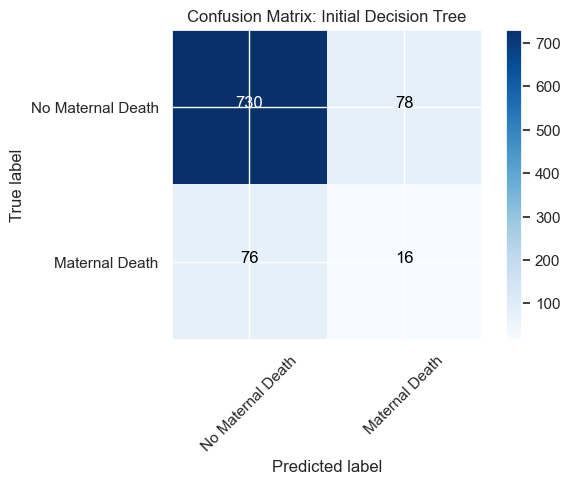

In [338]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree model
dec_tree = DecisionTreeClassifier(random_state=42)

# Train the model on the training data
dec_tree.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = dec_tree.predict(X_train)
valid_pred = dec_tree.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
dt_conf_matrix = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Initial Decision Tree Performance ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(dt_conf_matrix)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(dt_conf_matrix, classes=class_names, normalize=False, title='Confusion Matrix: Initial Decision Tree')
plt.show()

This decision tree algorithm, which purposely does not have max_depth and min_sample_leafs attributes, has a 100% training data accuracy and an 82% validation data accuracy. This suggests that the decision tree is overfitted to the training data.

After using the decision tree algorithm to train my model, my results differed to what I got after using logistic regression. My recall for maternal deaths improved from 2% to 17%, which means the model is successfully identifying more actual cases. However, this gain in recall came at a cost to precision, which dropped from 50% in logistic regression to 17%. While the logistic regression algorithm was rarely flagging cases, leading to higher precision but terrible recall, the decision tree algorithm is more aggressive in identifying potential risks, but at the expense of triggering many more false positives.

Consequently, my f1-score for predicting maternal deaths has improved from 4% to 17%. While this is a step in the right direction, it is still not capturing the reality of the healthcare context where missing true positives is critical.

This contrast reinforces that both models are still struggling to balance these trade-offs due to the underlying data imbalance (808 records for class 0 versus 92 for class 1). The model is clearly having difficulty learning the Class 1 (maternal deaths) patterns without being biased toward Class 0 (No maternal deaths). 

I will now proceed to use the random forest algorithm to train my model.

Initial Random Forest Algorithm:

--- Initial Random Forest Performance ---
Training Data Accuracy:   0.9998
Validation Data Accuracy: 0.8978

Confusion Matrix (Validation):
[[808   0]
 [ 92   0]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.90      1.00      0.95       808
           1       0.00      0.00      0.00        92

    accuracy                           0.90       900
   macro avg       0.45      0.50      0.47       900
weighted avg       0.81      0.90      0.85       900



C:\Users\apsmu\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\apsmu\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\apsmu\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

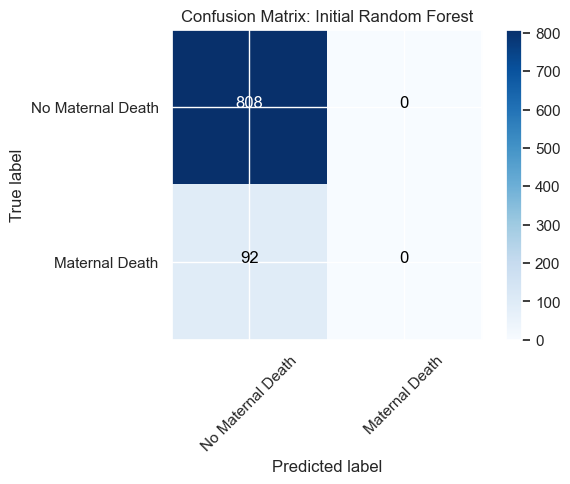

In [339]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model
# Setting a random_state
rf_model = RandomForestClassifier(random_state=42)

# Train the model on the training data
rf_model.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = rf_model.predict(X_train)
valid_pred = rf_model.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
rf_conf_matrix = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Initial Random Forest Performance ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(rf_conf_matrix)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(rf_conf_matrix, classes=class_names, normalize=False, title='Confusion Matrix: Initial Random Forest')
plt.show()

The results above show a very huge problem. First of all, the algorithm got a 99% training data accuracy and an 89% validation data accuracy which suggests overfitting to the training data. 
As a result of this, the random forest algorithm is completely ignoring any class 1 results and prioritizing global accuracy by predicting 'No Maternal Death' for every case hence the 0 scores for precision, recall and f1-score. 

This is probably being caused by the class imbalance and me failing to define max_depth and min_sample_leafs. I will now proceed to try the support vector machine (SVM) algorithm to see if I can get better results.

Initial Support Vector Machine Algorithm (RBF Kernel):

--- Initial SVM (RBF) Performance ---
Training Data Accuracy:   0.9024
Validation Data Accuracy: 0.8978

Confusion Matrix (Validation):
[[808   0]
 [ 92   0]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.90      1.00      0.95       808
           1       0.00      0.00      0.00        92

    accuracy                           0.90       900
   macro avg       0.45      0.50      0.47       900
weighted avg       0.81      0.90      0.85       900



C:\Users\apsmu\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\apsmu\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\apsmu\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

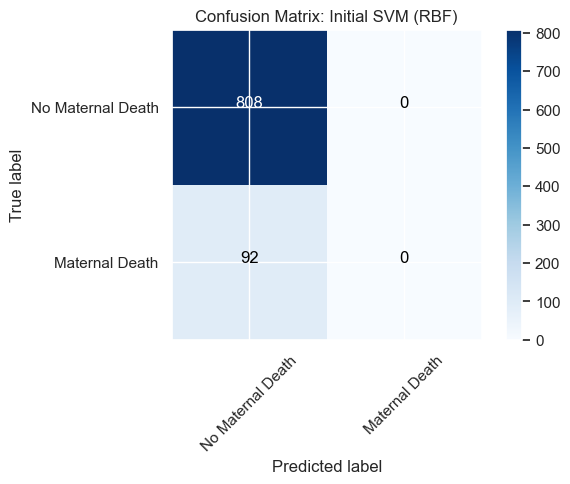

In [340]:
from sklearn.svm import SVC

# Initialize the SVM model using the default rbf kernel
svm_model = SVC(kernel='rbf', random_state=42)

# Train the model on the training data
svm_model.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = svm_model.predict(X_train)
valid_pred = svm_model.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
svm_conf_matrix = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Initial SVM (RBF) Performance ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(svm_conf_matrix)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(svm_conf_matrix, classes=class_names, normalize=False, title='Confusion Matrix: Initial SVM (RBF)')
plt.show()

The training data accuracy and the validation data accuracy are pretty close here which suggests that there is no overfitting.

Similarly to the random forest algorithm, the support vector machine algorithm (while using the default radial basis function kernel) is also completely ignoring the class 1 records. This is likely being caused by the class imbalance however, I want to try out the linear kernel to see if I will get similar results.

--- Initial SVM (Linear) Performance ---
Training Data Accuracy:   0.9024
Validation Data Accuracy: 0.8978

Confusion Matrix (Validation):
[[808   0]
 [ 92   0]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.90      1.00      0.95       808
           1       0.00      0.00      0.00        92

    accuracy                           0.90       900
   macro avg       0.45      0.50      0.47       900
weighted avg       0.81      0.90      0.85       900



C:\Users\apsmu\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\apsmu\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\apsmu\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

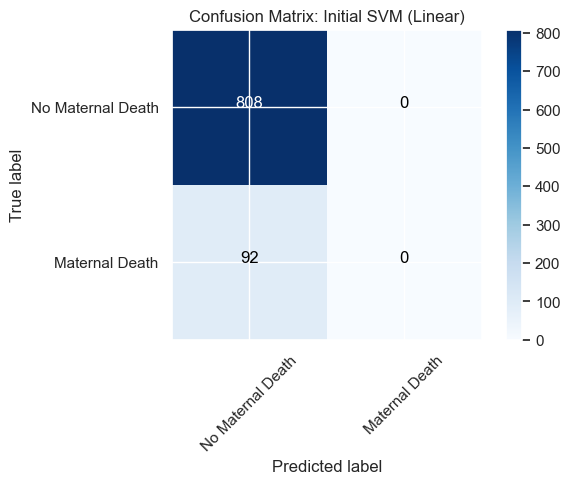

In [341]:
from sklearn.svm import SVC

# Initialize the SVM model using the linear kernel
svm_model = SVC(kernel='linear', random_state=42)

# Train the model on the training data
svm_model.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = svm_model.predict(X_train)
valid_pred = svm_model.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
svm_conf_matrix = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Initial SVM (Linear) Performance ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(svm_conf_matrix)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(svm_conf_matrix, classes=class_names, normalize=False, title='Confusion Matrix: Initial SVM (Linear)')
plt.show()

Changing the kernel had no effect on the results. The model is still ignoring class 1 records. 

I will now proceed to use the naive bayes algorithm to see how it performs.

Initial Naive Bayes Algorithm:

--- Initial Naive Bayes Performance ---
Training Data Accuracy:   0.5995
Validation Data Accuracy: 0.5622

Confusion Matrix (Validation):
[[451 357]
 [ 37  55]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.92      0.56      0.70       808
           1       0.13      0.60      0.22        92

    accuracy                           0.56       900
   macro avg       0.53      0.58      0.46       900
weighted avg       0.84      0.56      0.65       900



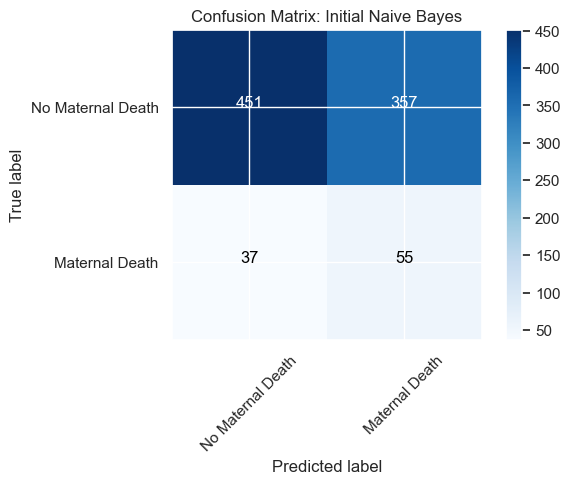

In [342]:
from sklearn.naive_bayes import GaussianNB

# Initialize the Naive Bayes model
# GaussianNB does not use a random_state parameter
nb_model = GaussianNB()

# Train the model on the training data
nb_model.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = nb_model.predict(X_train)
valid_pred = nb_model.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
nb_conf_matrix = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Initial Naive Bayes Performance ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(nb_conf_matrix)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(nb_conf_matrix, classes=class_names, normalize=False, title='Confusion Matrix: Initial Naive Bayes')
plt.show()

While the Naive Bayes model exhibits lower training and validation data accuracy, 59% and 56% respectively, compared to the other models I have tested, it successfully identified some of the Class 1 cases scoring a recall score of 60%. This increase in recall score comes at the cost of precision, which is 13% for class 1. This indicates that while the model has become significantly more sensitive, it is also generating a high number of false alarms. 

Given the severe data imbalance (808 records for class 0 vs. 92 for class 1), this result provides a valuable perspective: while Naive Bayes is less accurate overall, it is the only model that has successfully "learned" Class 1 cases. I now have a solid baseline of how different algorithms react to this imbalance, which will inform the next steps I will take in Task 3 in evaluating and attempting to improve model performance.

## Task 3: Evaluation

In this section, I will evaluate the results I got in Task 2 above after training my model using the 5 different algorithms which are relevant for classification tasks such as the one I am doing for this project. I will compare the results from each algorithm and make any necessary tweaks to attempt to improve performance. As it stands, my main issue is the extreme class imbalance in my data.

To recap, I will display the model performance for the 5 algorithms below:

In [343]:
import pandas as pd

# Define the model performance data
data = {
    "Algorithm Used": [
        "Logistic Regression (Initial)", 
        "Decision Tree (Initial)", 
        "Random Forest (Initial)", 
        "Support Vector Machine (RBF Initial)", 
        "Naive Bayes (Initial)"
    ],
    "Training Data Accuracy": [0.9033, 1.0000, 0.9900, 0.9000, 0.5995],
    "Validation Data Accuracy": [0.8978, 0.8289, 0.8978, 0.8978, 0.5622],
    "Precision (Maternal Death)": [0.50, 0.17, 0.00, 0.00, 0.13],
    "Recall (Maternal Death)": [0.02, 0.17, 0.00, 0.00, 0.60],
    "F1-score (Maternal Death)": [0.04, 0.17, 0.00, 0.00, 0.22]
}

results_df = pd.DataFrame(data)
results_df.set_index("Algorithm Used", inplace=True)

# Display the table
results_df

,Training Data Accuracy,Validation Data Accuracy,Precision (Maternal Death),Recall (Maternal Death),F1-score (Maternal Death)
Algorithm Used,,,,,
Logistic Regression (Initial),0.9033,0.8978,0.50,0.02,0.04
Decision Tree (Initial),1.0000,0.8289,0.17,0.17,0.17
Random Forest (Initial),0.9900,0.8978,0.00,0.00,0.00
Support Vector Machine (RBF Initial),0.9000,0.8978,0.00,0.00,0.00
Naive Bayes (Initial),0.5995,0.5622,0.13,0.60,0.22


The comparison table above confirms that high overall accuracy is a misleading metric for this dataset. Across the logistic regression, decision tree, random forest and SVM algorithms, the models achieved very high training data accuracy scores and decent validation data accuracy scores but they failed to identify almost all instances of maternal deaths (Class 1) which is very crucial for this project.

The Naive Bayes algorithm had the lowest training data and validation data accuracy scores but it was the only algorithm which had a higher recall score of 60% for the maternal death class (Class 1). 

Given the sensitive nature of this project, I will prioritize improving the recall score for Class 1, the ability to correctly flag actual maternal death cases, across the different algorithms. Additionally, I will also aim to get a reasonable f1-score to maintain model utility, the cost of a False Negative (missing a maternal death) far outweighs the cost of a False Positive. Therefore, a 'good' model for this project is one that maximizes sensitivity toward the maternal death class, even at the cost of overall accuracy.

Since I have a severe class imbalance in my dataset, I will use the class_weight='balanced' parameter to force the models to assign higher penalties to misclassifications of the maternal death class.

Tweaked Logistic Regression Algorithm:

C:\Users\apsmu\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


--- Tweaked Logistic Regression Performance ---
Training Data Accuracy:   0.7031
Validation Data Accuracy: 0.6656

Confusion Matrix (Validation):
[[544 264]
 [ 37  55]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.94      0.67      0.78       808
           1       0.17      0.60      0.27        92

    accuracy                           0.67       900
   macro avg       0.55      0.64      0.53       900
weighted avg       0.86      0.67      0.73       900



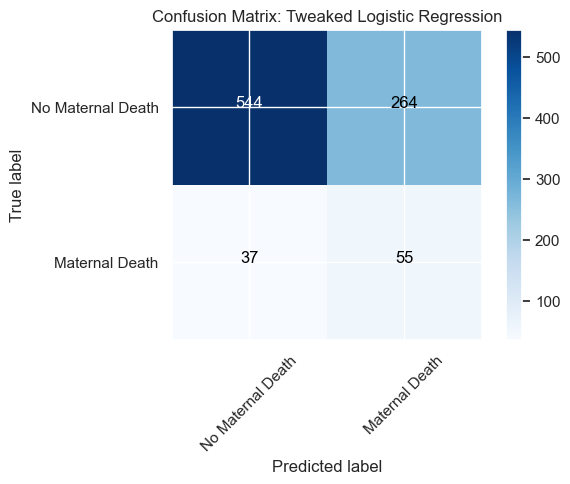

In [344]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Logistic Regression model using class_weight='balanced'
tweaked_log_model = LogisticRegression(class_weight='balanced', random_state=42)

# Define class names for the confusion matrix plots
class_names = ['No Maternal Death', 'Maternal Death']

# Train the model on the training data
tweaked_log_model.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = tweaked_log_model.predict(X_train)
valid_pred = tweaked_log_model.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
tweaked_log_conf_matrix = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Tweaked Logistic Regression Performance ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(tweaked_log_conf_matrix)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(tweaked_log_conf_matrix, classes=class_names, normalize=False, title='Confusion Matrix: Tweaked Logistic Regression')
plt.show()

The training data accuracy and the validation data accuracy are very close at 70% and 66% respectively. This indicates that there is no overfitting.

The confusion matrix reveals a clear shift in how the model handles the minority class. In the initial logistic regression algorithm, the algorithm was heavily biased towards Class 0, resulting in 90 False Negatives - meaning it missed almost every single maternal death case. By applying class_weight='balanced', the model successfully reduced these False Negatives to 37 and increased True Positives from 2 to 55. This confirms that the algorithm is now actively prioritizing Class 1 cases.

While this improvement significantly boosted recall score for Class 1 cases (from 2% to 60%), it came at the cost of overall accuracy, which dropped from 89% to 66%. This drop in accuracy is primarily due to an increase in False Positives (from 2 to 264), reflecting a more 'sensitive' model that is now more likely to flag a case as high-risk.

This is a step in the right direction and I will now proceed to test these tweaks using the decision tree algorithm. It is important to note that in my initial decision tree algorithm code, I purposely did not include the max_depth and min_samples_leaf so that I could see how the algorithm would perform in its default state. 

In addition to implementing the balanced class weight for the tweaked decision tree algorithm, I will also include max_depth and min_samples_leaf to see what results I will get.

Tweaked Decision Tree Algorithm:

--- Tweaked Decision Tree Performance ---
Training Data Accuracy:   0.4498
Validation Data Accuracy: 0.4467

Confusion Matrix (Validation):
[[330 478]
 [ 20  72]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.94      0.41      0.57       808
           1       0.13      0.78      0.22        92

    accuracy                           0.45       900
   macro avg       0.54      0.60      0.40       900
weighted avg       0.86      0.45      0.53       900



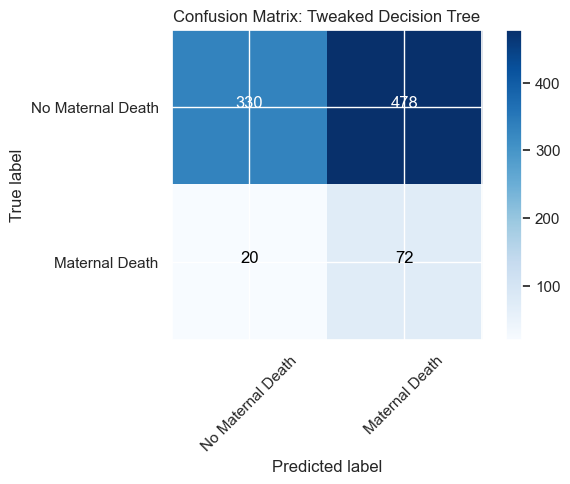

In [345]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Tweaked Decision Tree model
# Adding class_weight, max_depth, and min_samples_leaf
tweaked_dec_tree = DecisionTreeClassifier(
    class_weight='balanced', 
    max_depth=4,             
    min_samples_leaf=0.14,     
    random_state=42
)

# Train the model on the training data
tweaked_dec_tree.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = tweaked_dec_tree.predict(X_train)
valid_pred = tweaked_dec_tree.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
dt_conf_matrix_tweaked = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Tweaked Decision Tree Performance ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(dt_conf_matrix_tweaked)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(dt_conf_matrix_tweaked, classes=class_names, normalize=False, title='Confusion Matrix: Tweaked Decision Tree')
plt.show()

Comparing these results to the initial decision tree algorithm, I can see significant changes. The data accuracy score dropped from 82% in the initial decision tree algorithm to 44% which suggests that the overfitting which was present in the initial decision tree algorithm was addressed. Additionally, the recall score for Class 1 cases improved significantly from 17% to 78% and for Class 0 cases, dropped from 90% to 41%. As it stands, this tweaked decision tree algorithm has the best recall score for Class 1 cases.

Since introducing the balanced class weight, max_depth and min_samples_leaf has an evident effect on my model performance. I want to try different values for max_depth and min_samples_leaf to see if I can get better results.

--- Tweaked Decision Tree Performance (max_depth and min_sample_leaf changed) ---
Training Data Accuracy:   0.5602
Validation Data Accuracy: 0.5267

Confusion Matrix (Validation):
[[415 393]
 [ 33  59]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.93      0.51      0.66       808
           1       0.13      0.64      0.22        92

    accuracy                           0.53       900
   macro avg       0.53      0.58      0.44       900
weighted avg       0.84      0.53      0.62       900



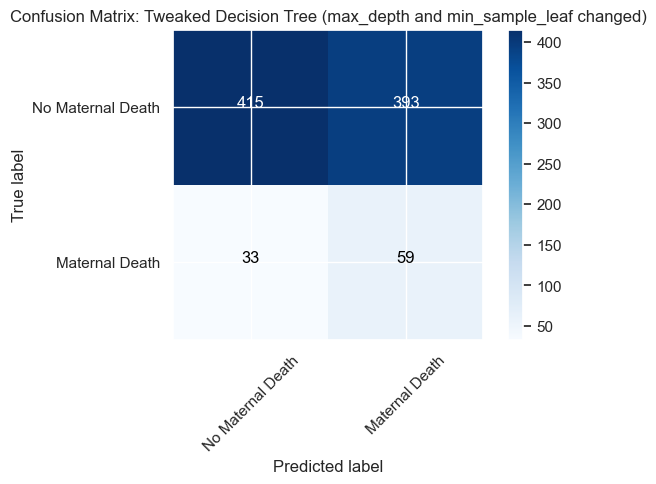

In [346]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Tweaked Decision Tree model
# Changing the max_depth, and min_samples_leaf
tweaked_dec_tree = DecisionTreeClassifier(
    class_weight='balanced', 
    max_depth=6,             
    min_samples_leaf=0.05,     
    random_state=42
)

# Train the model on the training data
tweaked_dec_tree.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = tweaked_dec_tree.predict(X_train)
valid_pred = tweaked_dec_tree.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
dt_conf_matrix_tweaked = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Tweaked Decision Tree Performance (max_depth and min_sample_leaf changed) ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(dt_conf_matrix_tweaked)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(dt_conf_matrix_tweaked, classes=class_names, normalize=False, title='Confusion Matrix: Tweaked Decision Tree (max_depth and min_sample_leaf changed)')
plt.show()

Increasing the max_depth from 4 to 6 and reducing the min_samples_leaf from 0.14 to 0.05 improved the accuracy score of my model from 44% to 52% but this resulted in the recall scores for Class 1 cases to reduce from 78% to 64% while the recall score for Class 0 cases increased from 41% to 51%. This suggests that these changes resulted in fewer false positives. 

I will maintain the initial max_depth and min_samples_leaf of 4 and 0.14 respectively when I tweak the random forest algorithm due to its superior recall score for Class 1 cases.

Tweaked Random Forest Algorithm:

--- Tweaked Random Forest Performance ---
Training Data Accuracy:   0.6248
Validation Data Accuracy: 0.6267

Confusion Matrix (Validation):
[[509 299]
 [ 37  55]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.93      0.63      0.75       808
           1       0.16      0.60      0.25        92

    accuracy                           0.63       900
   macro avg       0.54      0.61      0.50       900
weighted avg       0.85      0.63      0.70       900



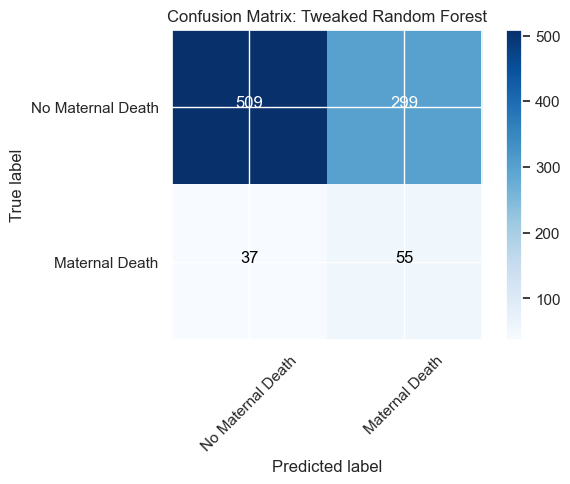

In [347]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Tweaked Random Forest model
# Adding class_weight, max_depth, and min_samples_leaf
tweaked_rf_model = RandomForestClassifier(
    class_weight='balanced', 
    max_depth=4,              
    min_samples_leaf=0.14,      
    random_state=42
)

# Train the model on the training data
tweaked_rf_model.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = tweaked_rf_model.predict(X_train)
valid_pred = tweaked_rf_model.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
rf_conf_matrix_tweaked = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Tweaked Random Forest Performance ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(rf_conf_matrix_tweaked)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(rf_conf_matrix_tweaked, classes=class_names, normalize=False, title='Confusion Matrix: Tweaked Random Forest')
plt.show()

The training data accuracy and validation data accuracy are nearly identical at 62% each which indicates that the max_depth and min_samples_leaf parameters successfully prevented the model from overfitting. In my initial random forest algorithm, I got an accuracy score of 89% however, the algorithm completely ignored Class 1 cases and it scored a 0 in precision, recall and f1-score.

After implementing the balanced class weight, max_depth and min_samples_leaf, the accuracy score dropped to 62% but precision, recall and f1-score for Class 1 cases increased from 0 to 16%, 60% and 25% respectively. While the recall score is still low compared to the tweaked logistic regression model, this is a positive sign.

I will now proceed to tweak the support vector machine (SVM) algorithm.

Tweaked Support Vector Machine (SVM) using the rbf kernel:

--- Tweaked SVM (RBF) Performance ---
Training Data Accuracy:   0.6645
Validation Data Accuracy: 0.6256

Confusion Matrix (Validation):
[[502 306]
 [ 31  61]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.94      0.62      0.75       808
           1       0.17      0.66      0.27        92

    accuracy                           0.63       900
   macro avg       0.55      0.64      0.51       900
weighted avg       0.86      0.63      0.70       900



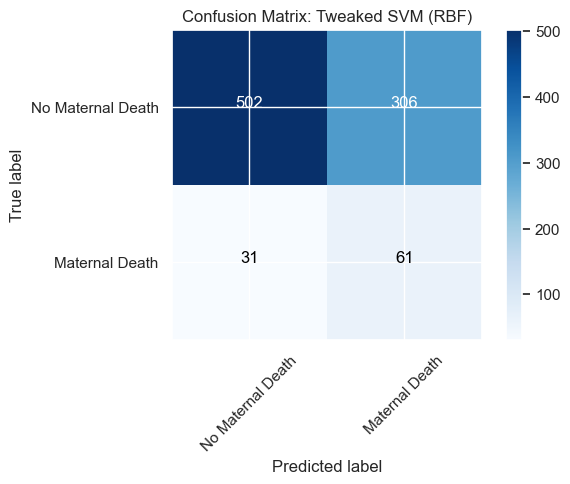

In [348]:
from sklearn.svm import SVC

# Initialize the Tweaked SVM model using the default rbf kernel
# Adding class_weight='balanced' 
tweaked_svm_model = SVC(kernel='rbf', class_weight='balanced', random_state=42)

# Train the model on the training data
tweaked_svm_model.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = tweaked_svm_model.predict(X_train)
valid_pred = tweaked_svm_model.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
svm_conf_matrix_tweaked = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Tweaked SVM (RBF) Performance ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(svm_conf_matrix_tweaked)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(svm_conf_matrix_tweaked, classes=class_names, normalize=False, title='Confusion Matrix: Tweaked SVM (RBF)')
plt.show()

The initial SVM algorithm had an accuracy score of 89%, but similarly to the random forest algorithm, it also completely ignored Class 1 cases. After applying the tweaks here, the overall validation accuracy dropped to 62%, but the precision, recall, and F1-score for Class 1 cases increased from 0 to 17%, 66%, and 27%, respectively.

Additionally, the training data accuracy of 66% and validation data accuracy of 62% indicate that the model is generalizing well and avoiding extreme overfitting.

I now want to use the linear kernel to see if I can improve the results.

Tweaked Support Vector Machine (SVM) using the linear kernel:

--- Tweaked SVM (Linear) Performance ---
Training Data Accuracy:   0.6902
Validation Data Accuracy: 0.6522

Confusion Matrix (Validation):
[[530 278]
 [ 35  57]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.94      0.66      0.77       808
           1       0.17      0.62      0.27        92

    accuracy                           0.65       900
   macro avg       0.55      0.64      0.52       900
weighted avg       0.86      0.65      0.72       900



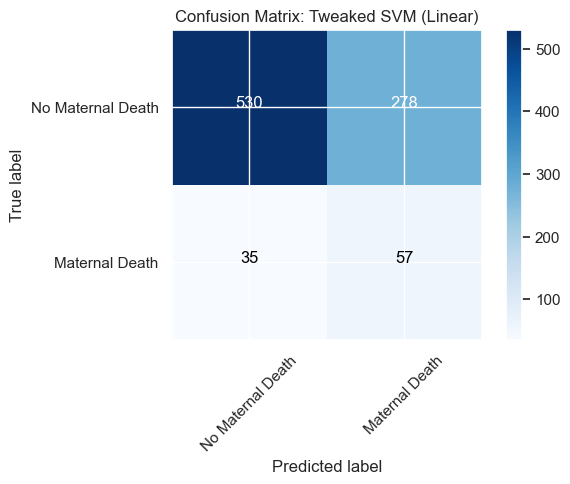

In [349]:
from sklearn.svm import SVC

# Initialize the Tweaked SVM model using the linear kernel
# Adding class_weight='balanced' 
tweaked_svm_model = SVC(kernel='linear', class_weight='balanced', random_state=42)

# Train the model on the training data
tweaked_svm_model.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred = tweaked_svm_model.predict(X_train)
valid_pred = tweaked_svm_model.predict(X_valid)

# Calculate accuracy for both
train_accuracy = accuracy_score(y_train, train_pred)
valid_accuracy = accuracy_score(y_valid, valid_pred)

# Calculate confusion matrix for validation data
svm_conf_matrix_tweaked = confusion_matrix(y_valid, valid_pred)

# Output the results
print("--- Tweaked SVM (Linear) Performance ---")
print(f"Training Data Accuracy:   {train_accuracy:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy:.4f}\n")

print("Confusion Matrix (Validation):")
print(svm_conf_matrix_tweaked)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(svm_conf_matrix_tweaked, classes=class_names, normalize=False, title='Confusion Matrix: Tweaked SVM (Linear)')
plt.show()

After changing to the linear kernel, accuracy increased slightly from 62% to 65% however, the recall score for Class 1 cases reduced from 66% to 62% which is not ideal for me. 

I will now proceed to tweak the naive bayes algorithm. In my initial round of training, the naive bayes algorithm scored the highest recall score for Class 1 cases despite the severe class imbalance.

Tweaked Naive Bayes Algorithm:

--- Tweaked Naive Bayes Performance ---
Training Data Accuracy:   0.5805
Validation Data Accuracy: 0.5478

Confusion Matrix (Validation):
[[436 372]
 [ 35  57]]

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.93      0.54      0.68       808
           1       0.13      0.62      0.22        92

    accuracy                           0.55       900
   macro avg       0.53      0.58      0.45       900
weighted avg       0.84      0.55      0.63       900



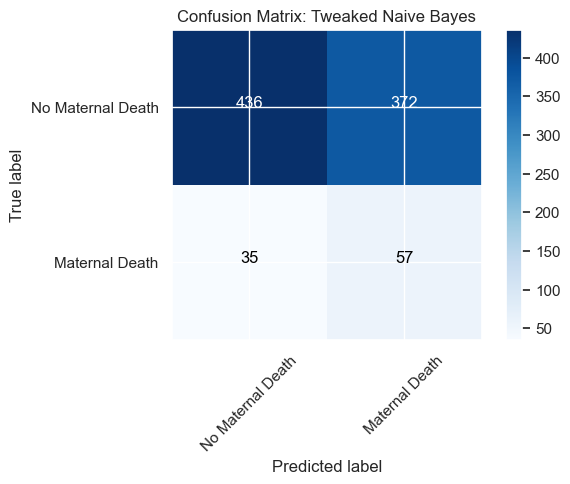

In [350]:
from sklearn.naive_bayes import GaussianNB

# Initialize the Tweaked Naive Bayes model
# Manually set equal priors [0.5, 0.5] to balance the classes instead of using class_weight
tweaked_nb_model = GaussianNB(priors=[0.5, 0.5])

# Train the model on the training data
tweaked_nb_model.fit(X_train, y_train)

# Generate predictions for both training and validation data
train_pred_tweaked = tweaked_nb_model.predict(X_train)
valid_pred_tweaked = tweaked_nb_model.predict(X_valid)

# Calculate accuracy for both
train_accuracy_tweaked = accuracy_score(y_train, train_pred_tweaked)
valid_accuracy_tweaked = accuracy_score(y_valid, valid_pred_tweaked)

# Calculate confusion matrix for validation data
nb_conf_matrix_tweaked = confusion_matrix(y_valid, valid_pred_tweaked)

# Output the results
print("--- Tweaked Naive Bayes Performance ---")
print(f"Training Data Accuracy:   {train_accuracy_tweaked:.4f}")
print(f"Validation Data Accuracy: {valid_accuracy_tweaked:.4f}\n")

print("Confusion Matrix (Validation):")
print(nb_conf_matrix_tweaked)

print("\nClassification Report (Validation):")
print(classification_report(y_valid, valid_pred_tweaked))

# Plot non-normalized confusion matrix
plt.figure()
plot_confusion_matrix(nb_conf_matrix_tweaked, classes=class_names, normalize=False, title='Confusion Matrix: Tweaked Naive Bayes')
plt.show()

Even after manually adjusting the priors to balance the classes, there was very little change compared to the initial naive bayes model. The overall validation data accuracy dropped slightly from 56% to 54%. The recall for Class 1 cases saw a minor increase from 60% to 62%, while the precision and f1-score for Class 1 cases remained completely stagnant at 13% and 22%, respectively.

Because Naive Bayes inherently relies on probability distributions rather than distance or tree-based rules, forcing equal class priors had a much less dramatic effect here than the class_weight='balanced' parameter had on the other algorithms.

I will now display an updated comprehensive performance comparison table for the tweaked models.

Updated Model Performance Table for Tweaked Algorithms:

In [351]:
import pandas as pd

# Define the comprehensive performance data for the tweaked models
data = {
    "Algorithm Used": [
        "Logistic Regression (Tweaked)", 
        "Decision Tree (Tweaked)", 
        "Random Forest (Tweaked)", 
        "Support Vector Machine (RBF Tweaked)", 
        "Naive Bayes (Tweaked)"
    ],
    "Training Data Accuracy": [0.7031, 0.4498, 0.6248, 0.6645, 0.5805],
    "Validation Data Accuracy": [0.6656, 0.4467, 0.6267, 0.6256, 0.5478],
    "Precision (Maternal Death)": [0.17, 0.13, 0.16, 0.17, 0.13],
    "Recall (Maternal Death)": [0.60, 0.78, 0.60, 0.66, 0.62],
    "F1-score (Maternal Death)": [0.27, 0.22, 0.25, 0.27, 0.22]
}

tweakedresults_df = pd.DataFrame(data)
tweakedresults_df.set_index("Algorithm Used", inplace=True)

# Display the table
tweakedresults_df

,Training Data Accuracy,Validation Data Accuracy,Precision (Maternal Death),Recall (Maternal Death),F1-score (Maternal Death)
Algorithm Used,,,,,
Logistic Regression (Tweaked),0.7031,0.6656,0.17,0.60,0.27
Decision Tree (Tweaked),0.4498,0.4467,0.13,0.78,0.22
Random Forest (Tweaked),0.6248,0.6267,0.16,0.60,0.25
Support Vector Machine (RBF Tweaked),0.6645,0.6256,0.17,0.66,0.27
Naive Bayes (Tweaked),0.5805,0.5478,0.13,0.62,0.22


Before settling on one model to proceed with in this project, I want to do qualitative error analysis on two of my models to see where and why they are making mistakes. I will compare the tweaked logistic regression because it had a recall score of 60% for Class 1 cases and the tweaked decision tree because it had the highest recall score for Class 1 cases at 70% 

In [352]:
# Creating a copy of my validation features to safely analyze
error_df = X_valid.copy()

# Add the actual outcomes
error_df['Actual_Death'] = y_valid

# Add the predictions from my two tweaked models
error_df['Pred_Decision_Tree'] = tweaked_dec_tree.predict(X_valid)
error_df['Pred_Log_Reg'] = tweaked_log_model.predict(X_valid)

# Identify specific discrepancies
# Filter for cases where Logistic Regression missed the death, but the Decision Tree caught it
# (Actual = 1, Log Reg Predicted = 0, Decision Tree Predicted = 1)
missed_by_log_caught_by_tree = error_df[
    (error_df['Actual_Death'] == 1) & 
    (error_df['Pred_Log_Reg'] == 0) & 
    (error_df['Pred_Decision_Tree'] == 1)
].copy()

# Reverse the scaling I used in Task 2 to see the actual real-world numbers
real_world_values = missed_by_log_caught_by_tree.copy()
num_cols = [
    'age', 'age_first_birth', 'birth_interval', 'distance_facility', 
    'household_size', 'poverty_rate', 'sba_coverage', 'county_edu_index'
]

# Apply the inverse transform to the numeric columns
real_world_values[num_cols] = scaler.inverse_transform(missed_by_log_caught_by_tree[num_cols])

# Results
print("Maternal Deaths MISSED by Logistic Regression but CAUGHT by Decision Tree:")
display(real_world_values.head())

Maternal Deaths MISSED by Logistic Regression but CAUGHT by Decision Tree:


,age,parity,education,anc_visits,c_section,postnatal48h,age_first_birth,birth_interval,wealth_quintile,household_size,...,county_Wajir,county_West Pokot,place_delivery_Private,place_delivery_Public,marital_status_Not in union,urbanization_Urban,skilled_attendant_Skilled,Actual_Death,Pred_Decision_Tree,Pred_Log_Reg
2446,41.0,3,2,2,0,1,38.0,27.0,2,4.0,...,False,False,False,True,False,False,True,1,1,0
5781,30.0,4,2,3,0,1,21.0,33.0,5,3.0,...,False,False,False,True,False,True,True,1,1,0
5816,26.0,2,1,6,0,0,21.0,25.0,4,9.0,...,False,False,False,True,True,False,True,1,1,0
1503,31.0,2,1,1,0,1,27.0,34.0,5,3.0,...,False,False,True,False,False,False,True,1,1,0
1671,24.0,2,1,1,0,1,19.0,54.0,2,4.0,...,False,False,False,True,False,True,True,1,1,0


To better understand why the models I used are making mistakes, I looked closely at the specific cases in my validation data where the predictions were wrong. I was particularly interested in the "False Negative" instances where the model predicted no risk, but a maternal death sadly occurred.  

After comparing the models:
- I noticed the Logistic Regression model frequently missed maternal death cases where a skilled birth attendant was present. It seems the model was "fooled" by this because it interpreted the presence of a skilled birth attendant as a strong sign of safety and, because it is a simpler, linear model, it weighed that one feature so heavily that it essentially ignored other warning signs.  
- On the other hand, the Decision Tree was much better at catching these cases. It didn’t rely on a single rule. Instead, it looked at other features like age, poverty levels, and the number of antenatal care (ANC) visits before making a prediction.  
    
In conclusion, this analysis confirms why we need models that can weigh multiple, complex risk factors together, rather than relying on one-size-fits-all indicators especially when developing models within sensitive areas like healthcare.

The comparison I did above was just for two models but now I am interested in seeing how the other models performed and if they encountered the same errors.

In [353]:
# Ensure error_df has all my predictions
error_df['Pred_Decision_Tree'] = tweaked_dec_tree.predict(X_valid)
error_df['Pred_Log_Reg'] = tweaked_log_model.predict(X_valid)
error_df['Pred_Random_Forest'] = tweaked_rf_model.predict(X_valid)
error_df['Pred_SVM'] = tweaked_svm_model.predict(X_valid)
error_df['Pred_NB'] = tweaked_nb_model.predict(X_valid)

# Filter for cases where ALL models missed a maternal death 
# (Actual = 1, and all predictions = 0)
unanimous_misses = error_df[
    (error_df['Actual_Death'] == 1) & 
    (error_df['Pred_Decision_Tree'] == 0) & 
    (error_df['Pred_Log_Reg'] == 0) &
    (error_df['Pred_Random_Forest'] == 0) &
    (error_df['Pred_SVM'] == 0) &
    (error_df['Pred_NB'] == 0)
].copy()

# Translate back to real-world numbers
real_world_misses = unanimous_misses.copy()
num_cols = [
    'age', 'age_first_birth', 'birth_interval', 'distance_facility', 
    'household_size', 'poverty_rate', 'sba_coverage', 'county_edu_index'
]
real_world_misses[num_cols] = scaler.inverse_transform(unanimous_misses[num_cols])

# Results
print("Maternal Deaths MISSED by ALL models:")
display(real_world_misses.head())

Maternal Deaths MISSED by ALL models:


,age,parity,education,anc_visits,c_section,postnatal48h,age_first_birth,birth_interval,wealth_quintile,household_size,...,place_delivery_Public,marital_status_Not in union,urbanization_Urban,skilled_attendant_Skilled,Actual_Death,Pred_Decision_Tree,Pred_Log_Reg,Pred_Random_Forest,Pred_SVM,Pred_NB
3990,31.0,1,2,2,0,0,29.0,30.0,2,4.0,...,True,False,False,True,1,0,0,0,0,0
484,38.0,1,2,3,0,0,34.0,42.0,1,2.0,...,False,False,False,True,1,0,0,0,0,0
2440,18.0,1,2,1,1,0,14.0,27.0,3,4.0,...,False,False,False,False,1,0,0,0,0,0
3608,23.0,3,2,5,0,1,21.0,43.0,3,5.0,...,False,True,True,True,1,0,0,0,0,0
1342,25.0,1,2,1,0,1,18.0,40.0,2,7.0,...,True,False,False,True,1,0,0,0,0,0


These were the maternal deaths that were sadly missed by all my models. There is no definite reason for failure due to various reasons like the models not being able to account for hidden variables that may not be captured within the dataset e.g. underlying health conditions. 

Index 2440 concerns me the most because based on the low number of anc visits and the lack of a skilled birth attendant present, the models should have flagged this as a high risk for maternal death but they didn't.

That concludes my qualitative error analysis. I will now proceed to select one to progress with for the rest of the project. Based on the tweaked model performance comparison table I did earlier, the top two algorithms were the tweaked logistic regression and the tweaked support vector machine (RBF Kernel). 

Since I was prioritizing a high recall score specifically for Class 1 cases and a decent f1-score, I have decided to use tweaked support vector machine (RBF Kernel) algorithm because it strikes a good balance between the training data accuracy and the validation data accuracy as well as having a decent recall score of 66% and an f1-score of 27%. 

I will now test the model against my test dataset which has not been seen or used until this moment.

Test Data:

--- Tweaked SVM (RBF Kernel) Test Set Performance ---
              precision    recall  f1-score   support

           0       0.94      0.67      0.78       796
           1       0.21      0.64      0.31       104

    accuracy                           0.67       900
   macro avg       0.57      0.66      0.55       900
weighted avg       0.85      0.67      0.73       900



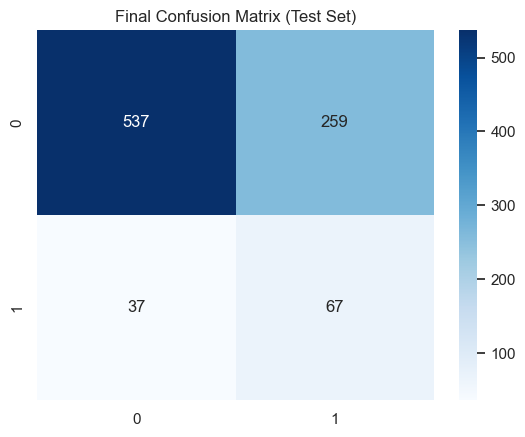

In [354]:
# Run the model on the test set
test_pred = tweaked_svm_model.predict(X_test)

# Model Performance
print("--- Tweaked SVM (RBF Kernel) Test Set Performance ---")
print(metrics.classification_report(y_test, test_pred))

# Confusion Matrix for the final report
cm = metrics.confusion_matrix(y_test, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Final Confusion Matrix (Test Set)')
plt.show()

These test dataset results show that the tweaked SVM algorithm (RBF Kernel) performed consistently with my validation results. The recall score for Class 1 (Maternal Death) cases decreased slightly from 66% to 64%, while the f1-score for Class 1 cases improved from 27% to 31%. This represents a significant improvement over the initial SVM model, which failed to identify any Class 1 cases.  

Regarding the false positive rate, the model currently flags 259 false positives for every 67 true positives. While this trade-off is necessary to maximize the detection of high-risk cases, it is not ideal because excessive false alarms could strain limited resources and hinder the efficient allocation of healthcare support at the county and national levels.

I will now proceed to save this final model before concluding this project with my reflection.

In [355]:
import joblib

joblib.dump(tweaked_svm_model, 'kenyan_maternal_mortality_analysis_svm_model.pkl')

print("Model saved successfully!")

Model saved successfully!


## Task 4: Reflection

Interpretation of Results:

The test set results demonstrate that my SVM model (RBF Kernel) is operationally viable for screening high-risk maternal cases. With a recall score of 64%, the model successfully flags the majority of high-risk individuals, providing county governments with a proactive mechanism to allocate resources. 

It is important to note that while the precision score of 21% for Class 1 cases, indicates a need for careful resource management to avoid over-screening patients, the model represents a substantial improvement over the initial svm model by prioritizing sensitivity to potential life-threatening events for expectant mothers in Kenya.

Why the Model Makes Certain Predictions:

Unlike the Logistic Regression model, the tweaked SVM model was better at identifying Class 1 cases because of its Radial Basis Function (RBF) kernel. This kernel allows it to handle the extreme non-linearity of the features in my dataset. Maternal death is rarely the result of a single, isolated factor; it is a complex, multi-layered event. Because of this, trying to force the data into linear models, like Logistic Regression, often leads to errors because the real-world relationships are not simple straight lines.

However, this complexity doesn't make the model perfect. My analysis of the cases where all models missed the maternal deaths showed me that even with these advanced techniques, there are still patterns in the data that none of these models can fully capture.

Fairness and Ethical Considerations:

Something I had noted earlier on is that the dataset was heavily populated with respondents who were located in the rural areas of Kenya where there are high poverty rates. This means that in the event that this model is used to allocate healthcare resources to different counties in Kenya, some remote counties might be overshadowed by other counties that are already well-equipped or easier to treat. 

This could consequently lead to resource allocation efforts becoming worse.

Limitations and Future Work:

The major limitation I encountered was when I was investigating the maternal death cases that were missed by all the models. One case stood out because there were multiple risk factors present i.e. few antenatal clinic visits and the lack of a skilled birth attendant present but all the models still failed to flag it. For a project like this, missing just one maternal death case is very detrimental and a sensitive issue because human life is sacred and should be protected.

Another limitation is the severe class imbalance which I attempted to address. The dataset did not contain sufficient maternal death data which could have been used to improve the model performance and help address the first limitation I mentioned. Having more data to work with could have provided more hidden variables which are vital in healthcare such as underlying medical conditions, medical team response times etc...

To conclude, I would like to thank my professor, Arjumand and her TAs for teaching me these machine learning foundations. The module was very insightful and I had fun working on this project. 